In [1]:
#architecture will be input -3 hidden -4 hidden -4 output -1


In [29]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split

In [30]:
np.random.seed(42)

In [31]:
#load the data set

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)
y = y.reshape(-1, 1)

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (500, 2)
y shape: (500, 1)


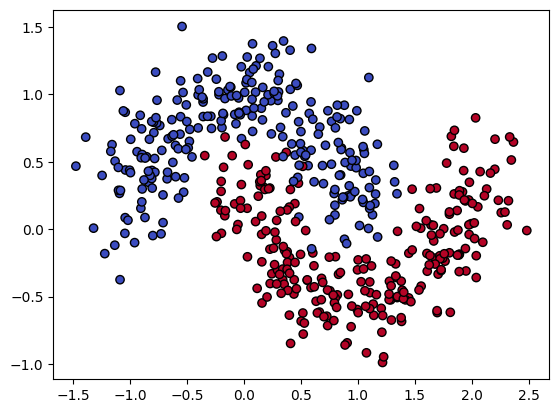

In [32]:
plt.scatter(X[:, 0], X[:, 1], c=y.ravel(), cmap='coolwarm', edgecolor='k')
plt.show()


In [33]:
#separate the test data
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [34]:
#Split the train and validation
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.125, random_state=42  # 0.125 * 0.8 = 0.1
)

print(f"Train: {X_train.shape[0]} samples")
print(f"Val:   {X_val.shape[0]} samples")
print(f"Test:  {X_test.shape[0]} samples")

Train: 350 samples
Val:   50 samples
Test:  100 samples


In [35]:
#Activsstion function
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def sigmoid_derivative(a):
    # 'a' is already sigmoid(z)
    return a * (1 - a)

In [36]:
input_size=2
hidden_size=4
hidden2_size =4
output =1

w1=  np.random.randn(input_size,hidden_size)*0.5
b1 =  np.zeros((1,hidden_size))

w2 = np.random.randn(hidden_size,hidden2_size)*0.5
b2 = np.zeros((1,hidden2_size))

w3 = np.random.randn(hidden2_size,output)*0.5
b3 = np.zeros((1,output))



In [37]:
w3

array([[-0.27219136],
       [ 0.05546129],
       [-0.57549679],
       [ 0.18784901]])

In [38]:
b1

array([[0., 0., 0., 0.]])

In [39]:
#Training Loop

epcohs = 2000
learning_rate = 1
train_losses =[]
val_losses=[]
epsilon = 1e-15

for epoch in range(epcohs):
  #forward pass
  z1 = X_train @ w1 + b1
  a1 = sigmoid(z1)

  z2 = a1 @ w2 + b2
  a2 = sigmoid(z2)

  z3 = a2 @ w3 + b3
  a3 = sigmoid(z3)

  #calculate the train loss
  train_loss = -np.mean(y_train * np.log(a3 + epsilon) + (1 - y_train) * np.log(1 - a3 + epsilon))
  train_losses.append(train_loss)

  #backward pass
  dz3 = (a3 - y_train)/len(y_train)
  dw3 = a2.T @ dz3
  db3 = np.sum(dz3, axis=0, keepdims=True)

  #hidden layer 2

  dz2 = (dz3 @ w3.T) * sigmoid_derivative(a2)
  dw2 = a1.T @ dz2
  db2 = np.sum(dz2, axis=0, keepdims=True)

  # Hidden layer 1
  dz1 = (dz2 @ w2.T) * sigmoid_derivative(a1)
  dW1 = X_train.T @ dz1
  db1 = np.sum(dz1, axis=0, keepdims=True)

  # ---- Update weights ----
  w3 -= learning_rate * dw3;  b3 -= learning_rate * db3
  w2 -= learning_rate * dw2;  b2 -= learning_rate * db2
  w1 -= learning_rate * dW1;  b1 -= learning_rate * db1

  #validation loss

  a1_v = sigmoid(X_val @ w1 + b1)
  a2_v = sigmoid(a1_v @ w2 + b2)
  a3_v = sigmoid(a2_v @ w3 + b3)
  val_loss = -np.mean(y_val * np.log(a3_v + epsilon) +
                        (1 - y_val) * np.log(1 - a3_v + epsilon))
  val_losses.append(val_loss)


  if epoch % 200 == 0:
        print(f"Epoch {epoch:5d} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")



Epoch     0 | Train Loss: 0.6988 | Val Loss: 0.6965
Epoch   200 | Train Loss: 0.3497 | Val Loss: 0.2265
Epoch   400 | Train Loss: 0.3124 | Val Loss: 0.1701
Epoch   600 | Train Loss: 0.2990 | Val Loss: 0.1699
Epoch   800 | Train Loss: 0.2084 | Val Loss: 0.1280
Epoch  1000 | Train Loss: 0.1181 | Val Loss: 0.0597
Epoch  1200 | Train Loss: 0.0882 | Val Loss: 0.0365
Epoch  1400 | Train Loss: 0.0748 | Val Loss: 0.0291
Epoch  1600 | Train Loss: 0.0682 | Val Loss: 0.0280
Epoch  1800 | Train Loss: 0.0642 | Val Loss: 0.0286


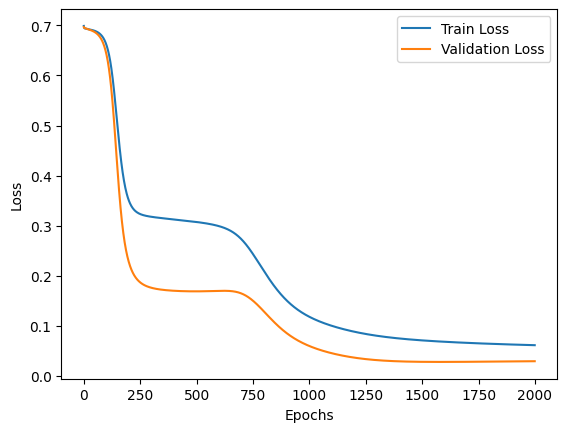

In [40]:
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [41]:
#Evaluation on test set

def predict (X_input):
  a1 = sigmoid(X_input @ w1 + b1)
  a2 = sigmoid(a1 @ w2 + b2)
  a3 = sigmoid(a2 @ w3 + b3)
  return (a3)
for name, X_,Y_ in [("Train", X_train, y_train),
                    ("Validation", X_val, y_val),
                    ("Test", X_test, y_test)]:
  preds = predict(X_)
  predicted_classes = (preds>0.5).astype(int)
  accuracy = np.mean(predicted_classes == Y_)
  print(f"{name} Accuracy: {accuracy * 100:.2f}%")

Train Accuracy: 97.71%
Validation Accuracy: 98.00%
Test Accuracy: 99.00%


In [42]:
w1

array([[ 3.52387679,  2.95065112,  5.44172288,  1.55513489],
       [-2.45096533, -2.18104149,  1.41567808, -0.34311041]])

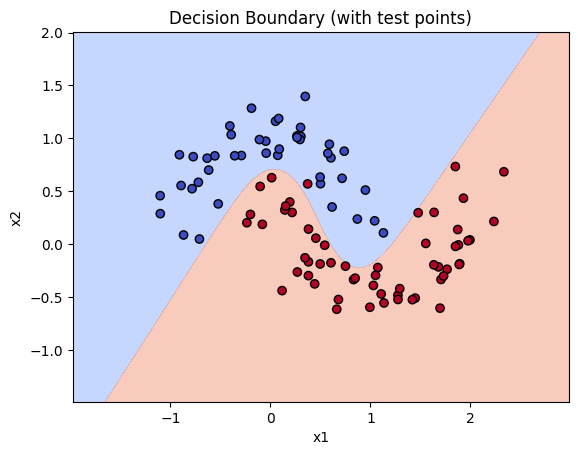

In [43]:
#visualize the decision boundary

# Create a grid of points covering the data
x_min, x_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
y_min, y_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 200),
                     np.linspace(y_min, y_max, 200))
grid = np.c_[xx.ravel(), yy.ravel()]

# Predict for each grid point
zz = predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=[0, 0.5, 1], cmap='coolwarm', alpha=0.5)
# Plot test set points to show how well boundary generalizes
plt.scatter(X_test[:, 0], X_test[:, 1], c=y_test.ravel(),
            cmap='coolwarm', edgecolor='k')
plt.title("Decision Boundary (with test points)")
plt.xlabel("x1"); plt.ylabel("x2")
plt.show()